In [ ]:
#pip install treelib

# To do list
Short term:
- fix bias gradient calculations
- implement cross entropy
- add qol features like interactions with scalar values

Long term:
- convolution properties
- transformer proeprties
- cuda kernels




In [ ]:
import numpy as np
from treelib import Tree
import matplotlib.pyplot as plt

#====================================================================================================================================================================
#TENSOR DATA TYPE
#===================================================================================================================================================================

class Tensor:
  def __init__(self, value, op = 'none (base value)', children=()):
    self.value = value
    self.shape = value.shape
    self.op = op
    self.children = children
    self.grad = np.zeros_like(value)
    self.back = lambda: None
    self.back_order = []

  @classmethod
  def random_tensor(cls, m, n):
    return cls(np.random.rand(m,n))

  @classmethod
  def random_input_tensor(cls, m, n):
    t = cls(np.random.rand(m,n+1))
    t.value[:,n] = 1
    return t

  @classmethod
  def ones_tensor(cls, m, n):
    return cls(np.ones((m,n)))

  @classmethod
  def zeros_tensor(cls, m, n):
    return cls(np.zeros((m,n)))

  #DISPLAY FUNCTIONS ================================================================================================================================================

  def __repr__(self):
    return f"tensor of shape {self.shape} with parent op: {self.op}"

  def print_tensor(self):
    print(self.value)

  def print_grad(self):
    print(self.grad)

  def display_tree(self):
    var = self
    tree = Tree()

    # Use a global node counter to guarantee unique IDs for every node
    node_counter = 1
    tree.create_node(var.__repr__(), str(node_counter))

    # Queue holds tuples of (tensor_node, node_id_string)
    queue = [(var, str(node_counter))]

    while queue:
      current_node, current_id = queue.pop(0)
      for child in current_node.children:
        node_counter += 1
        child_id = str(node_counter)
        tree.create_node(child.__repr__(), child_id, parent=current_id)
        queue.append((child, child_id))

    tree.show()

  #MATHEMATICAL FUNCTIONS ======================================================================================================================================================

  def __add__(self, other):
    result = Tensor(self.value + other.value, op='+', children=(self, other))
    # NOTE: THis add fucntions gradient calculations are flawed. It only works for neaural netowrks specifically, and as a lazy guy ill leave it at that too.
    def back():
      temp_grad = result.grad
      if(self.value.shape<result.grad.shape):
          temp_grad = temp_grad.sum(axis=0)
          self.grad += temp_grad
      else:
        self.grad += temp_grad

      temp_grad = result.grad
      if(other.value.shape<result.grad.shape):
          temp_grad = temp_grad.sum(axis=0)
          other.grad += temp_grad
      else:
        other.grad += temp_grad

    result.back = back
    return result

  def __matmul__(self, other):
    result = Tensor(self.value @ other.value, op='*', children=(self, other))

    def back():
      # Corrected matrix multiplication gradients using transposes (.T)
      self.grad += result.grad @ other.value.T
      other.grad += self.value.T @ result.grad

    result.back = back
    return result

  def sigmoid(self):
    float_val = 1 / (1 + np.exp(-self.value))
    float_val = np.where(float_val == 1, 0.9999999, float_val)
    float_val = np.where(float_val == 0, 0.0000001, float_val)

    result = Tensor(float_val, op='sigmoid', children=(self,))

    def back():
      self.grad +=(result.value* (1 - result.value) )* result.grad

    result.back = back
    return result

  def relu(self):
    result_float = np.where(self.value>0, self.value, 0)
    result = Tensor(result_float, op='relu', children=(self,))

    def back():
      self.grad += np.where(self.value>0, 1,0)*result.grad

    result.back = back
    return result

  def leaky_relu(self):
    result_float = np.where(self.value>0, self.value, self.value*0.01)
    result = Tensor(result_float, op='leaky_relu', children=(self,))

    def back():
      self.grad += np.where(self.value>0, 1,-0.01)*result.grad

    result.back = back
    return result

  def tanh(self):
    result_float = (2/(1+np.exp(-2*self.value))) - 1
    result = Tensor(result_float, op='tanh', children = (self,))

    def back():
      self.grad += (1 - result_float**2) * result.grad

    result.back = back
    return result

  def square_error(self, other):
    result = Tensor((self.value-other.value)**2, op = 'MSE', children=(self,other))

    def back():
      self.grad += 2*(self.value-other.value)*result.grad
      other.grad -= 2*(self.value-other.value)*result.grad

    result.back = back

    return result

  def summation(self):
    result = Tensor(np.sum(self.value), op = 'sum', children=(self,))

    def back():
      self.grad += np.ones_like(self.value)*result.grad

    result.back = back
    return result

  #BACK PROPOGATION=====================================================================================================================================================

  def backward(self):
    visited = []
    self.back_order = []
    def topo_sort(root):
      if root not in visited:
        visited.append(root)
        for child in root.children:
          topo_sort(child)
        self.back_order.append(root)

    topo_sort(self)
    self.grad = np.ones_like(self.value)

    for var in reversed(self.back_order):
      var.back()

#=================================================================================================================================================================
#-------------------------------------------------------------------------------------------------------------------------------------------------------------------
#================================================================================================================================================================

# ReLU = r
# sigmoid = s
# leakyr = l
# tanh = t

class Proto_Network_1:
  def __init__(self, input_count, weight_count_list, act_funcs):
    self.input_count = input_count
    self.weight_count_list = weight_count_list

    self.weights = []
    self.biases = []
    self.act_funcs = act_funcs

    temp_list = [input_count] + weight_count_list
    temp_count = len(temp_list)
    i = 0
    while(i<temp_count-1):
      self.weights.append(Tensor.random_tensor(temp_list[i],temp_list[i+1]))
      self.biases.append(Tensor.random_tensor(1,temp_list[i+1]))
      i+=1


  def __call__(self, x):
    xc = Tensor(x.value.copy())
    i = 0
    for weight, bias in zip(self.weights, self.biases):
      xc = xc@weight
      xc = xc+bias
      if(self.act_funcs[i]=='r'):
        xc = xc.relu()
      elif(self.act_funcs[i]=='s'):
        xc = xc.sigmoid()
      elif(self.act_funcs[i]=='l'):
        xc = xc.leaky_relu()
      elif(self.act_funcs[i] == 't'):
        xc = xc.tanh()
      i += 1
    return xc

  def train(self, x, y, lr, epochs):
    loss_history = []
    for _ in range(epochs):
      xc = self.__call__(x)
      xc = xc.square_error(y)
      loss = xc.summation()
      loss_history.append(loss.value)
      loss.backward()

      for weight, bias in zip(self.weights, self.biases):
        weight.value = weight.value - lr*weight.grad
        bias.value = bias.value - lr*bias.grad
        weight.grad = np.zeros_like(weight.value)
        bias.grad = np.zeros_like(bias.value)

    plt.plot(loss_history)
    plt.xlabel('Epoch')
    plt.ylabel('Loss Sum')
    plt.title('Training Loss Over Epochs')
    plt.show()








In [ ]:
feature_count = 7
data_set_count = 400
hidden_count = 20
target_count = 9

x = Tensor.random_tensor(data_set_count,feature_count)
y = Tensor.random_tensor(data_set_count,target_count)




In [ ]:
a = Tensor(np.array([[1,-2,-3],[3,4,-5],[8,-9,3]], dtype=float))
b = a.tanh()
c = b.sigmoid()
c.backward()
a.print_grad()

[[9.11282181e-02 1.41200258e-02 1.94420930e-03]
 [1.94420930e-03 2.63728611e-04 3.57029280e-05]
 [8.85030223e-08 1.19775828e-08 1.94420930e-03]]


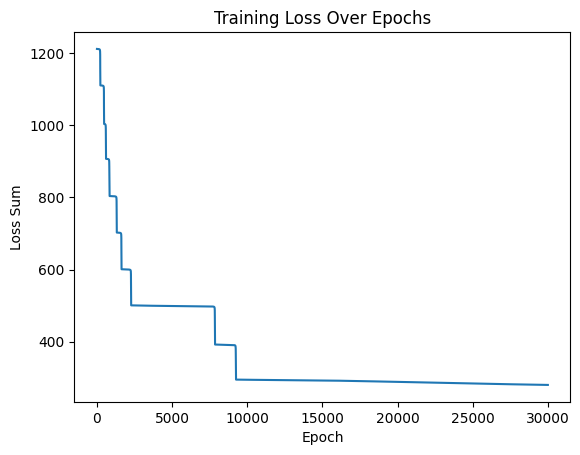

In [ ]:
epochs = 10000

network = Proto_Network_1(feature_count, [hidden_count, target_count], ['s','s'])

network.train(x,y,0.001,30000)


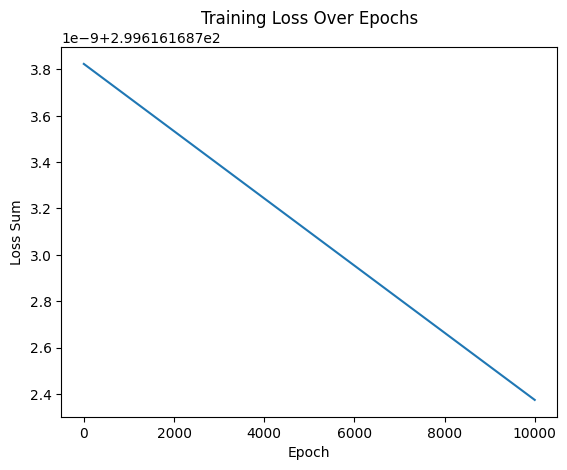

In [ ]:
network.train(x,y,0.001,10000)